# 06. Outlier Analysis

Phân phối, boxplot và đánh giá outlier cho các biến numeric trong transaction.


In [54]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [55]:
raw_dir = Path("../data/raw/Dunnhumby")


In [56]:
NUMERIC_PLOT_SAMPLE_SIZE = 200_000
NUMERIC_HISTOGRAM_BINS = 60
TRANSACTION_NUMERIC_COLUMNS = [
    "QUANTITY",
    "SALES_VALUE",
    "RETAIL_DISC",
    "COUPON_DISC",
    "COUPON_MATCH_DISC",
]
transaction_detail_columns = [
    "household_key",
    "BASKET_ID",
    "DAY",
    "PRODUCT_ID",
    "STORE_ID",
    *TRANSACTION_NUMERIC_COLUMNS,
]
transaction_detail = pd.read_csv(
    raw_dir / "transaction_data.csv",
    usecols=transaction_detail_columns,
)

numeric_values = {
    ("transaction", column): (
        pd.to_numeric(transaction_detail[column], errors="coerce")
        .dropna()
        .astype("float64")
    )
    for column in TRANSACTION_NUMERIC_COLUMNS
}

numeric_diagnostic_rows = []
for (table_name, column), values in numeric_values.items():
    quantiles = values.quantile([0.01, 0.25, 0.50, 0.75, 0.99])
    n_values = int(values.size)
    n_zero = int(values.eq(0).sum())
    n_negative = int(values.lt(0).sum())
    n_positive = int(values.gt(0).sum())
    numeric_diagnostic_rows.append({
        "table": table_name,
        "column": column,
        "count": n_values,
        "min": float(values.min()),
        "p1": float(quantiles.loc[0.01]),
        "p25": float(quantiles.loc[0.25]),
        "median": float(quantiles.loc[0.50]),
        "p75": float(quantiles.loc[0.75]),
        "p99": float(quantiles.loc[0.99]),
        "max": float(values.max()),
        "mean": float(values.mean()),
        "std": float(values.std()),
        "skew": float(values.skew()),
        "n_zero": n_zero,
        "zero_pct": n_zero / n_values * 100 if n_values else pd.NA,
        "n_negative": n_negative,
        "negative_pct": n_negative / n_values * 100 if n_values else pd.NA,
        "n_positive": n_positive,
        "positive_pct": n_positive / n_values * 100 if n_values else pd.NA,
    })
numeric_diagnostics = pd.DataFrame(numeric_diagnostic_rows)
numeric_diagnostics


,table,column,count,min,p1,p25,median,p75,p99,max,mean,std,skew,n_zero,zero_pct,n_negative,negative_pct,n_positive,positive_pct
0,transaction,QUANTITY,2595732,0.00,1.00,1.00,1.00,1.00,10.0,89638.00,100.428558,1153.436211,13.642979,14466,0.557299,0,0.000000,2581266,99.442701
1,transaction,SALES_VALUE,2595732,0.00,0.20,1.29,2.00,3.49,20.0,840.00,3.104120,4.182274,15.907471,18850,0.726192,0,0.000000,2576882,99.273808
2,transaction,RETAIL_DISC,2595732,-180.00,-4.99,-0.69,-0.01,0.00,0.0,3.99,-0.538705,1.249191,-13.350060,1292670,49.799825,1303026,50.198788,36,0.001387
3,transaction,COUPON_DISC,2595732,-55.93,-0.50,0.00,0.00,0.00,0.0,0.00,-0.016416,0.216841,-44.206637,2559310,98.596851,36422,1.403149,0,0.000000
4,transaction,COUPON_MATCH_DISC,2595732,-7.70,0.00,0.00,0.00,0.00,0.0,0.00,-0.002919,0.039690,-24.434657,2578283,99.327781,17449,0.672219,0,0.000000


## 1. Histogram linear, log-count và boxplot

Biểu đồ dùng mẫu cố định tối đa 200.000 giá trị mỗi biến để giữ thời gian render ổn định; thống kê outlier vẫn dùng toàn bộ dữ liệu.


C:\Users\manhh\AppData\Local\Temp\ipykernel_37340\4213063395.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box_axis.boxplot(
C:\Users\manhh\AppData\Local\Temp\ipykernel_37340\4213063395.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box_axis.boxplot(
C:\Users\manhh\AppData\Local\Temp\ipykernel_37340\4213063395.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box_axis.boxplot(
C:\Users\manhh\AppData\Local\Temp\ipykernel_37340\4213063395.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box_axis.boxplot(
C:\Users\manhh\AppDa

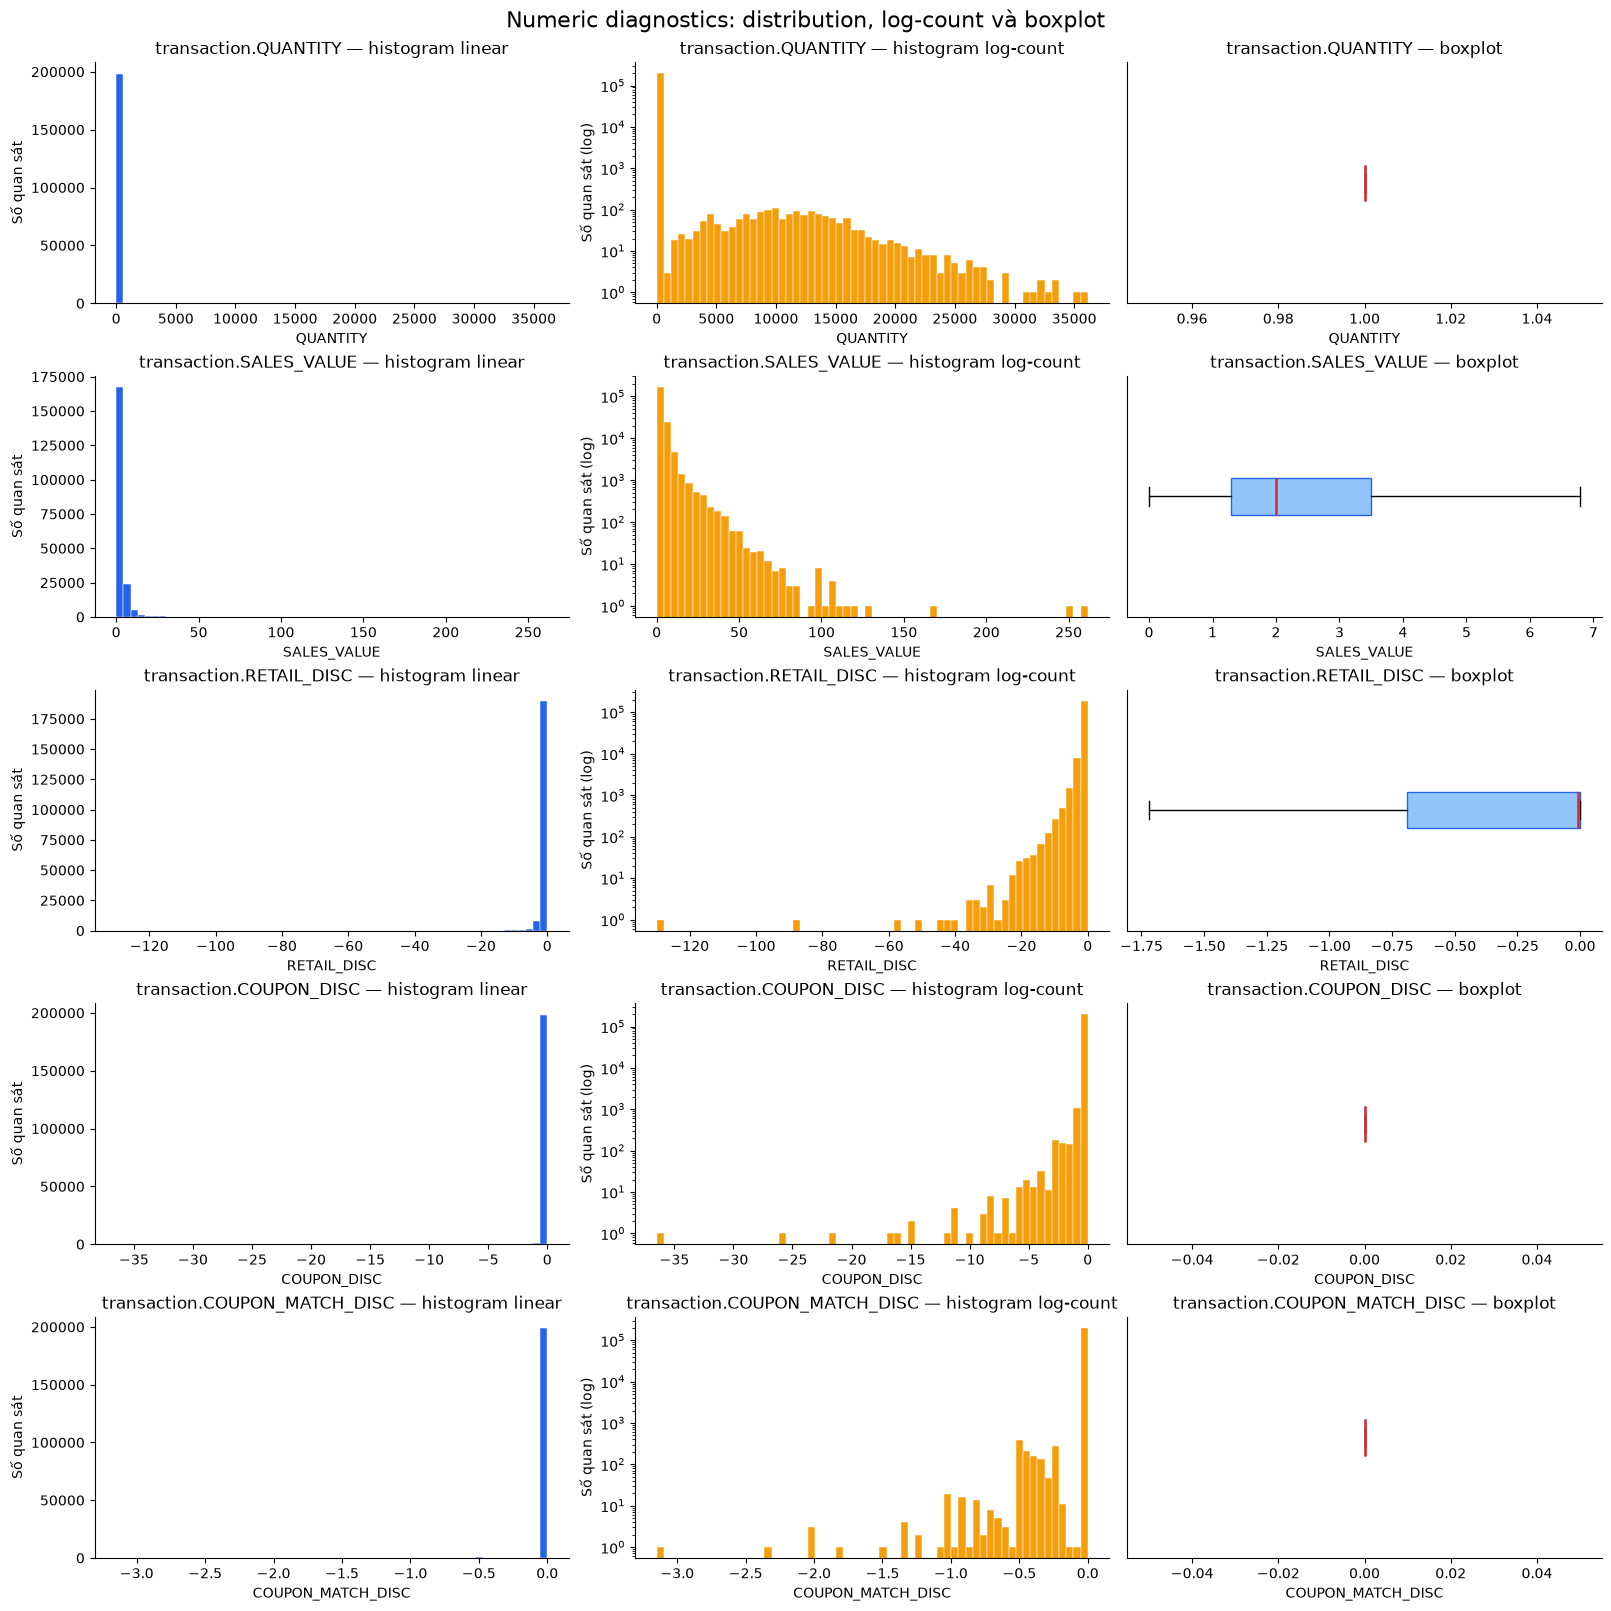

In [57]:
n_numeric_variables = len(numeric_values)
numeric_diagnostics_figure, numeric_diagnostics_axes = plt.subplots(
    n_numeric_variables,
    3,
    figsize=(16, max(4, 3.2 * n_numeric_variables)),
    squeeze=False,
    layout="constrained",
)
for row_index, ((table_name, column), values) in enumerate(numeric_values.items()):
    plot_values = (
        values.sample(NUMERIC_PLOT_SAMPLE_SIZE, random_state=42)
        if len(values) > NUMERIC_PLOT_SAMPLE_SIZE
        else values
    )
    linear_axis, log_axis, box_axis = numeric_diagnostics_axes[row_index]
    linear_axis.hist(
        plot_values, bins=NUMERIC_HISTOGRAM_BINS,
        color="#2563EB", edgecolor="white", linewidth=0.35,
    )
    log_axis.hist(
        plot_values, bins=NUMERIC_HISTOGRAM_BINS,
        color="#F59E0B", edgecolor="white", linewidth=0.35,
    )
    log_axis.set_yscale("log")
    box_axis.boxplot(
        plot_values.to_numpy(),
        vert=False,
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "#93C5FD", "edgecolor": "#2563EB"},
        medianprops={"color": "#DC2626", "linewidth": 1.8},
    )
    linear_axis.set_title(f"{table_name}.{column} — histogram linear")
    log_axis.set_title(f"{table_name}.{column} — histogram log-count")
    box_axis.set_title(f"{table_name}.{column} — boxplot")
    linear_axis.set_ylabel("Số quan sát")
    log_axis.set_ylabel("Số quan sát (log)")
    box_axis.set_yticks([])
    for axis in (linear_axis, log_axis, box_axis):
        axis.set_xlabel(column)
        axis.spines[["top", "right"]].set_visible(False)
numeric_diagnostics_figure.suptitle(
    "Numeric diagnostics: distribution, log-count và boxplot", fontsize=16
)
plt.show()

### 7.2. Kết luận outlier theo từng biến numeric

Outlier được nhận diện bằng ngưỡng `Q1 − 1,5 × IQR` và `Q3 + 1,5 × IQR`. Loại nghi vấn dựa trên phía xuất hiện outlier và skewness. Đây là đề xuất tiền xử lý, không tự động xóa dữ liệu: `loại` chỉ áp dụng cho giá trị không hữu hạn; `cap` dành cho đuôi hiếm và lệch mạnh; `giữ` khi không có outlier hoặc outlier có vẻ là cấu trúc tự nhiên của phân phối.

In [58]:
def summarize_numeric_outliers(table_name, column, values):
    non_finite_mask = values.isin([float("inf"), float("-inf")])
    finite_values = values.loc[~non_finite_mask]
    q1 = float(finite_values.quantile(0.25))
    q3 = float(finite_values.quantile(0.75))
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    low_outlier_mask = values.lt(lower_bound) & ~non_finite_mask
    high_outlier_mask = values.gt(upper_bound) & ~non_finite_mask
    outlier_mask = low_outlier_mask | high_outlier_mask | non_finite_mask
    n_rows = int(values.size)
    n_outliers = int(outlier_mask.sum())
    outlier_pct = n_outliers / n_rows * 100 if n_rows else 0.0
    n_low = int(low_outlier_mask.sum())
    n_high = int(high_outlier_mask.sum())
    skew = float(finite_values.skew())

    if int(non_finite_mask.sum()) > 0:
        suspected_type = "lỗi kỹ thuật: ±inf / không hữu hạn"
        proposed_action = "loại"
        action_reason = "giá trị không hữu hạn không dùng trực tiếp cho mô hình"
    elif n_outliers == 0:
        suspected_type = "không có outlier theo quy tắc IQR"
        proposed_action = "giữ"
        action_reason = "chưa có bằng chứng cần can thiệp"
    else:
        if n_low > 0 and n_high > 0:
            suspected_type = "đuôi dày hai phía / nhiều nhóm hành vi"
        elif n_high > 0:
            suspected_type = "đuôi phải: giá trị lớn hiếm"
        else:
            suspected_type = "đuôi trái: giá trị nhỏ hoặc âm hiếm"

        if outlier_pct <= 10 and abs(skew) >= 1:
            proposed_action = "cap"
            action_reason = "đuôi tương đối hiếm và phân phối lệch mạnh; cap tại p1/p99 trước khi model"
        else:
            proposed_action = "giữ"
            action_reason = "outlier có vẻ mang tính cấu trúc; cân nhắc transform/robust model"

    has_outlier = n_outliers > 0
    conclusion = (
        f"{'Có' if has_outlier else 'Không'} outlier; "
        f"{n_outliers:,}/{n_rows:,} dòng ({outlier_pct:.2f}%); "
        f"nghi là {suspected_type}; đề xuất {proposed_action}: {action_reason}."
    )
    return {
        "table": table_name,
        "column": column,
        "has_outlier": has_outlier,
        "outlier_rows": n_outliers,
        "outlier_pct": outlier_pct,
        "lower_iqr_bound": lower_bound,
        "upper_iqr_bound": upper_bound,
        "suspected_outlier_type": suspected_type,
        "proposed_action": proposed_action,
        "conclusion": conclusion,
    }

numeric_outlier_conclusions = pd.DataFrame([
    summarize_numeric_outliers(table_name, column, values)
    for (table_name, column), values in numeric_values.items()
])
numeric_outlier_conclusions

,table,column,has_outlier,outlier_rows,outlier_pct,lower_iqr_bound,upper_iqr_bound,suspected_outlier_type,proposed_action,conclusion
0,transaction,QUANTITY,True,544765,20.986951,1.000,1.000,đuôi dày hai phía / nhiều nhóm hành vi,giữ,"Có outlier; 544,765/2,595,732 dòng (20.99%); n..."
1,transaction,SALES_VALUE,True,190644,7.344518,-2.010,6.790,đuôi phải: giá trị lớn hiếm,cap,"Có outlier; 190,644/2,595,732 dòng (7.34%); ng..."
2,transaction,RETAIL_DISC,True,206313,7.948163,-1.725,1.035,đuôi dày hai phía / nhiều nhóm hành vi,cap,"Có outlier; 206,313/2,595,732 dòng (7.95%); ng..."
3,transaction,COUPON_DISC,True,36422,1.403149,0.000,0.000,đuôi trái: giá trị nhỏ hoặc âm hiếm,cap,"Có outlier; 36,422/2,595,732 dòng (1.40%); ngh..."
4,transaction,COUPON_MATCH_DISC,True,17449,0.672219,0.000,0.000,đuôi trái: giá trị nhỏ hoặc âm hiếm,cap,"Có outlier; 17,449/2,595,732 dòng (0.67%); ngh..."


#### Kết luận xử lý outlier cho từng cột numeric:
- **`QUANTITY`**: Có outlier; chiếm **20.99%** dòng (544,765 dòng theo quy tắc IQR do Q1=Q3=1); nghi là outlier cấu trúc tự nhiên (gom tại 1) kết hợp đuôi phải cực lớn (xăng, mua sỉ B2B); đề xuất **giữ** (xử lý riêng nhánh sản phẩm xăng và log-transform / binning khi đưa vào mô hình).
- **`SALES_VALUE`**: Có outlier; chiếm **7.34%** dòng (190,644 dòng); nghi là outlier đuôi phải do các giao dịch mua sắm giá trị lớn hiếm; đề xuất **cap** (capping/winsorize tại p99 để tránh kéo lệch gradient/trọng số mô hình).
- **`RETAIL_DISC`**: Có outlier; chiếm **7.95%** dòng (206,313 dòng); nghi là outlier đuôi trái (giảm giá khuyến mại sâu theo đợt) kèm 36 dòng lỗi kỹ thuật mang giá trị dương (>0); đề xuất **cap** (capping đuôi âm tại p1; riêng 36 dòng dương thì loại bỏ hoặc đưa về 0).
- **`COUPON_DISC`**: Có outlier; chiếm **1.40%** dòng (36,422 dòng do phân phối zero-inflated, >98% dòng bằng 0); nghi là outlier đuôi trái (áp mã giảm giá coupon giá trị cao); đề xuất **cap** (capping đuôi âm tại p1 khi dùng làm biến liên tục, hoặc tách cờ nhị phân `has_coupon`).
- **`COUPON_MATCH_DISC`**: Có outlier; chiếm **0.67%** dòng (17,449 dòng do phân phối zero-inflated, >99% dòng bằng 0); nghi là outlier đuôi trái (chính sách match coupon giá trị lớn); đề xuất **cap** (capping đuôi âm tại p1 khi dùng làm biến liên tục, hoặc tách cờ nhị phân).


## 3. Outlier transaction sau khi loại giao dịch xăng khỏi phép đánh giá


In [59]:
FUEL_TAXONOMY_PATTERN = r"\b(?:GASOLINE|MOTOR\s+FUEL|FUEL|DIESEL|PETROL)\b"
product_taxonomy = pd.read_csv(
    raw_dir / "product.csv",
    usecols=[
        "PRODUCT_ID", "MANUFACTURER", "BRAND", "DEPARTMENT",
        "COMMODITY_DESC", "SUB_COMMODITY_DESC",
    ],
)
taxonomy_text = (
    product_taxonomy[["DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]]
    .fillna("")
    .astype("string")
    .agg(" | ".join, axis=1)
    .str.upper()
)
product_taxonomy["is_fuel"] = taxonomy_text.str.contains(
    FUEL_TAXONOMY_PATTERN, regex=True, na=False
)
fuel_product_ids = set(
    product_taxonomy.loc[product_taxonomy["is_fuel"], "PRODUCT_ID"]
)
transaction_detail["is_fuel"] = transaction_detail["PRODUCT_ID"].isin(
    fuel_product_ids
)
transaction_numeric_columns = TRANSACTION_NUMERIC_COLUMNS


#### Outlier transaction sau khi loại phần xăng khỏi phép đánh giá

In [60]:
non_fuel_numeric_outlier_conclusions = pd.DataFrame([
    summarize_numeric_outliers(
        "transaction_non_fuel",
        column,
        pd.to_numeric(
            transaction_detail.loc[~transaction_detail["is_fuel"], column],
            errors="coerce",
        ).dropna().astype("float64"),
    )
    for column in transaction_numeric_columns
])
non_fuel_numeric_outlier_conclusions

,table,column,has_outlier,outlier_rows,outlier_pct,lower_iqr_bound,upper_iqr_bound,suspected_outlier_type,proposed_action,conclusion
0,transaction_non_fuel,QUANTITY,True,521612,20.290108,1.000,1.000,đuôi dày hai phía / nhiều nhóm hành vi,giữ,"Có outlier; 521,612/2,570,770 dòng (20.29%); n..."
1,transaction_non_fuel,SALES_VALUE,True,173792,6.760309,-1.935,6.585,đuôi phải: giá trị lớn hiếm,cap,"Có outlier; 173,792/2,570,770 dòng (6.76%); ng..."
2,transaction_non_fuel,RETAIL_DISC,True,213219,8.293974,-1.650,0.990,đuôi dày hai phía / nhiều nhóm hành vi,cap,"Có outlier; 213,219/2,570,770 dòng (8.29%); ng..."
3,transaction_non_fuel,COUPON_DISC,True,36422,1.416774,0.000,0.000,đuôi trái: giá trị nhỏ hoặc âm hiếm,cap,"Có outlier; 36,422/2,570,770 dòng (1.42%); ngh..."
4,transaction_non_fuel,COUPON_MATCH_DISC,True,17449,0.678746,0.000,0.000,đuôi trái: giá trị nhỏ hoặc âm hiếm,cap,"Có outlier; 17,449/2,570,770 dòng (0.68%); ngh..."


## 4. Phân tích riêng GASOLINE và NON_GAS

`GASOLINE` dùng cờ `is_fuel` được xác định từ taxonomy sản phẩm. `NON_GAS` gồm toàn bộ dòng còn lại. Extreme products của NON_GAS được định nghĩa là sản phẩm có ít nhất một dòng `QUANTITY ≥ p99` của phân phối NON_GAS.


### 4.1. NON_GAS: phân vị, IQR và extreme products


In [61]:
gas_lines = transaction_detail.loc[transaction_detail["is_fuel"]].copy()
non_gas_lines = transaction_detail.loc[~transaction_detail["is_fuel"]].copy()
gas_lines["QUANTITY"] = pd.to_numeric(gas_lines["QUANTITY"], errors="coerce")
non_gas_lines["QUANTITY"] = pd.to_numeric(
    non_gas_lines["QUANTITY"], errors="coerce"
)

non_gas_quantity = non_gas_lines["QUANTITY"].dropna()
non_gas_q1 = float(non_gas_quantity.quantile(0.25))
non_gas_q3 = float(non_gas_quantity.quantile(0.75))
non_gas_iqr = non_gas_q3 - non_gas_q1
non_gas_p99 = float(non_gas_quantity.quantile(0.99))
non_gas_quantity_summary = pd.Series({
    "count": int(non_gas_quantity.size),
    "median": float(non_gas_quantity.median()),
    "p95": float(non_gas_quantity.quantile(0.95)),
    "p99": non_gas_p99,
    "max": float(non_gas_quantity.max()),
    "q1": non_gas_q1,
    "q3": non_gas_q3,
    "IQR": non_gas_iqr,
    "IQR_upper_bound": non_gas_q3 + 1.5 * non_gas_iqr,
}, name="NON_GAS_QUANTITY").to_frame()

non_gas_extreme_lines = (
    non_gas_lines.loc[
        non_gas_lines["QUANTITY"].ge(non_gas_p99),
        [
            "PRODUCT_ID", "BASKET_ID", "household_key", "QUANTITY",
            "SALES_VALUE", "STORE_ID", "DAY",
        ],
    ]
    .merge(
        product_taxonomy[[
            "PRODUCT_ID", "MANUFACTURER", "BRAND", "DEPARTMENT",
            "COMMODITY_DESC", "SUB_COMMODITY_DESC",
        ]].drop_duplicates("PRODUCT_ID"),
        on="PRODUCT_ID",
        how="left",
        validate="many_to_one",
    )
)
non_gas_extreme_products = (
    non_gas_extreme_lines
    .groupby(
        [
            "PRODUCT_ID", "MANUFACTURER", "BRAND", "DEPARTMENT",
            "COMMODITY_DESC", "SUB_COMMODITY_DESC",
        ],
        dropna=False,
    )
    .agg(
        n_extreme_lines=("QUANTITY", "size"),
        median_quantity=("QUANTITY", "median"),
        max_quantity=("QUANTITY", "max"),
        total_quantity=("QUANTITY", "sum"),
        total_sales_value=("SALES_VALUE", "sum"),
        n_baskets=("BASKET_ID", "nunique"),
        n_households=("household_key", "nunique"),
    )
    .sort_values(
        ["max_quantity", "n_extreme_lines", "total_quantity"],
        ascending=[False, False, False],
    )
)

display(non_gas_quantity_summary)
print("=== TOP 30 EXTREME PRODUCTS — NON_GAS (QUANTITY ≥ p99) ===")
display(non_gas_extreme_products.head(30))


,NON_GAS_QUANTITY
count,2570770.0
median,1.0
p95,3.0
p99,5.0
max,144.0
q1,1.0
q3,1.0
IQR,0.0
IQR_upper_bound,1.0


=== TOP 30 EXTREME PRODUCTS — NON_GAS (QUANTITY ≥ p99) ===


,,,,,,n_extreme_lines,median_quantity,max_quantity,total_quantity,total_sales_value,n_baskets,n_households
PRODUCT_ID,MANUFACTURER,BRAND,DEPARTMENT,COMMODITY_DESC,SUB_COMMODITY_DESC,,,,,,,
911878,2,National,PRODUCE,CORN,CORN WHITE,307,6.0,144,2442,705.61,307,228
1014675,2259,National,DRUG GM,STATIONERY & SCHOOL SUPPLIES,BINDERS & PORTFOLIOS,28,10.0,90,354,45.30,28,28
879948,531,National,DRUG GM,CANDY - CHECKLANE,CANDY BARS (SINGLES)(INCLUDING,33,8.0,74,424,131.63,33,25
6034249,89,National,DRUG GM,CANDY - PACKAGED,SEASONAL MISCELLANEOUS,14,11.5,72,240,47.13,14,14
907994,531,National,DRUG GM,CANDY - CHECKLANE,CANDY BARS (SINGLES)(INCLUDING,8,5.0,72,114,31.05,8,6
1080279,2289,National,DRUG GM,CANDY - CHECKLANE,CANDY BARS (SINGLES)(INCLUDING,6,10.0,72,121,51.85,6,6
8358895,857,National,DRUG GM,CANDY - PACKAGED,CANDY BARS (SINGLES)(INCLUDING,9,8.0,65,163,23.56,9,9
1053763,1046,National,GROCERY,PWDR/CRYSTL DRNK MX,SOFT DRINK POWDER POUCHES,125,6.0,60,1078,201.56,125,64
850841,1276,National,GROCERY,ISOTONIC DRINKS,ISOTONIC DRINKS SINGLE SERVE,32,5.0,60,258,278.97,32,13


### 4.2. GASOLINE: QUANTITY, SALES_VALUE, price ratio và scale thử nghiệm

Price ratio được tính bằng `SALES_VALUE / QUANTITY`; các dòng `QUANTITY = 0` được đưa về missing để tránh chia cho 0. Scale thử nghiệm đổi đơn vị thành `QUANTITY / 1000`, không làm thay đổi hình dạng phân phối.


,GAS_QUANTITY
count,24962.00
min,1.00
p1,1.00
median,10267.00
p99,25210.02
max,89638.00


,GAS_SALES_VALUE
count,24962.0000
total,633957.2600
min,0.0300
p1,4.5322
median,24.1150
p99,61.1039
max,250.0000


,SALES_VALUE_PER_QUANTITY
count,24962.000000
min,0.001659
p1,0.001839
median,0.002309
p99,25.000000
max,100.000000


,GAS_QUANTITY_PER_1000
count,24962.00000
min,0.00100
p1,0.00100
median,10.26700
p99,25.21002
max,89.63800


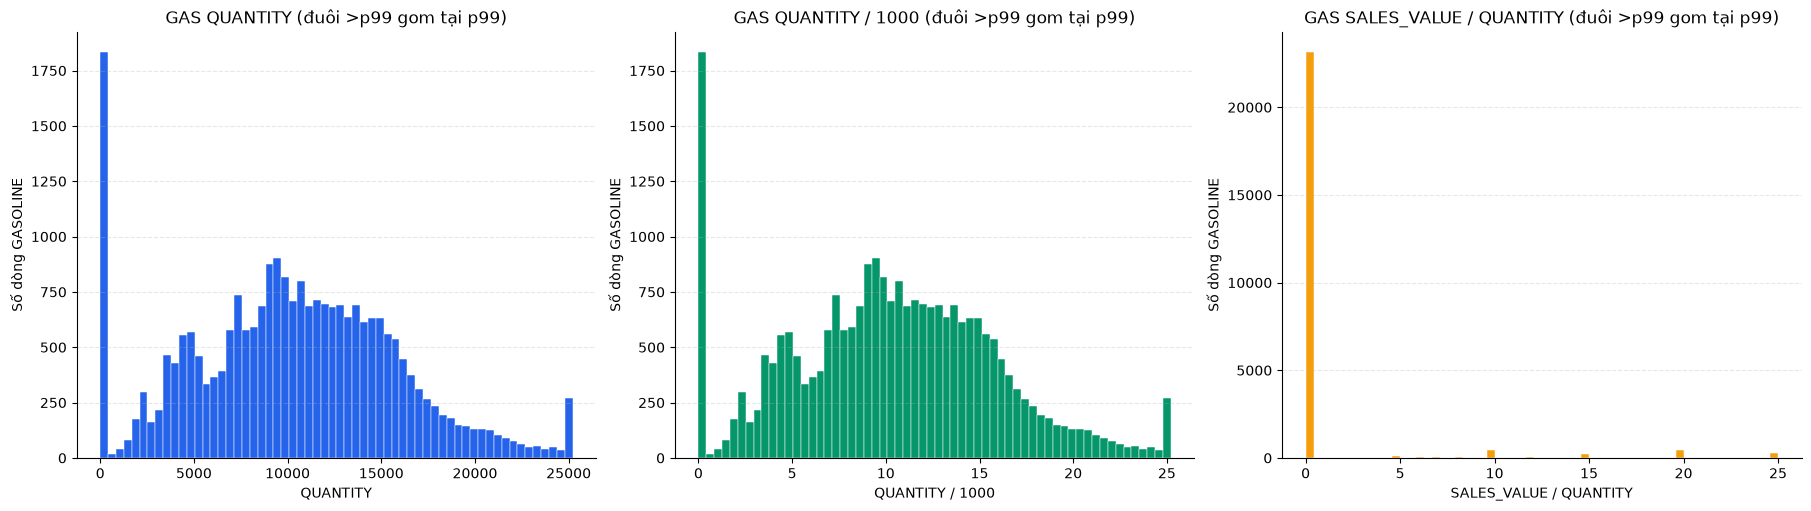

In [62]:
gas_lines["SALES_VALUE"] = pd.to_numeric(
    gas_lines["SALES_VALUE"], errors="coerce"
)
gas_lines["sales_value_per_quantity"] = (
    gas_lines["SALES_VALUE"] / gas_lines["QUANTITY"].replace(0, np.nan)
)
gas_lines["quantity_per_1000"] = gas_lines["QUANTITY"] / 1000

gas_quantity = gas_lines["QUANTITY"].dropna()
gas_sales_value = gas_lines["SALES_VALUE"].dropna()
gas_sales_value_per_quantity = gas_lines["sales_value_per_quantity"].dropna()
gas_quantity_per_1000 = gas_lines["quantity_per_1000"].dropna()

gas_quantity_summary = pd.Series({
    "count": int(gas_quantity.size),
    "min": float(gas_quantity.min()),
    "p1": float(gas_quantity.quantile(0.01)),
    "median": float(gas_quantity.median()),
    "p99": float(gas_quantity.quantile(0.99)),
    "max": float(gas_quantity.max()),
}, name="GAS_QUANTITY").to_frame()
gas_sales_summary = pd.Series({
    "count": int(gas_sales_value.size),
    "total": float(gas_sales_value.sum()),
    "min": float(gas_sales_value.min()),
    "p1": float(gas_sales_value.quantile(0.01)),
    "median": float(gas_sales_value.median()),
    "p99": float(gas_sales_value.quantile(0.99)),
    "max": float(gas_sales_value.max()),
}, name="GAS_SALES_VALUE").to_frame()
gas_ratio_summary = pd.Series({
    "count": int(gas_sales_value_per_quantity.size),
    "min": float(gas_sales_value_per_quantity.min()),
    "p1": float(gas_sales_value_per_quantity.quantile(0.01)),
    "median": float(gas_sales_value_per_quantity.median()),
    "p99": float(gas_sales_value_per_quantity.quantile(0.99)),
    "max": float(gas_sales_value_per_quantity.max()),
}, name="SALES_VALUE_PER_QUANTITY").to_frame()
gas_scaled_quantity_summary = pd.Series({
    "count": int(gas_quantity_per_1000.size),
    "min": float(gas_quantity_per_1000.min()),
    "p1": float(gas_quantity_per_1000.quantile(0.01)),
    "median": float(gas_quantity_per_1000.median()),
    "p99": float(gas_quantity_per_1000.quantile(0.99)),
    "max": float(gas_quantity_per_1000.max()),
}, name="GAS_QUANTITY_PER_1000").to_frame()

display(
    gas_quantity_summary,
    gas_sales_summary,
    gas_ratio_summary,
    gas_scaled_quantity_summary,
)

gas_diagnostic_figure, gas_diagnostic_axes = plt.subplots(
    1, 3, figsize=(18, 5), layout="constrained"
)
gas_plot_specs = [
    (gas_quantity, "GAS QUANTITY", "QUANTITY", "#2563EB"),
    (
        gas_quantity_per_1000,
        "GAS QUANTITY / 1000",
        "QUANTITY / 1000",
        "#059669",
    ),
    (
        gas_sales_value_per_quantity,
        "GAS SALES_VALUE / QUANTITY",
        "SALES_VALUE / QUANTITY",
        "#F59E0B",
    ),
]
for axis, (values, title, xlabel, color) in zip(
    gas_diagnostic_axes, gas_plot_specs, strict=True
):
    p99_limit = float(values.quantile(0.99))
    axis.hist(
        values.clip(upper=p99_limit),
        bins=60,
        color=color,
        edgecolor="white",
        linewidth=0.35,
    )
    axis.set(
        title=f"{title} (đuôi >p99 gom tại p99)",
        xlabel=xlabel,
        ylabel="Số dòng GASOLINE",
    )
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()


### 4.3. SALES_VALUE — GASOLINE và NON_GAS

So sánh riêng phân phối `SALES_VALUE` của hai nhóm: count, min, p1, median, p95, p99, max, IQR và ngưỡng IQR. Extreme products được xác định theo `SALES_VALUE ≥ p99` riêng trong từng nhóm.


group,NON_GAS,GASOLINE
count,2570770.000,24962.0000
min,0.000,0.0300
p1,0.200,4.5322
median,2.000,24.1150
p95,7.540,47.8700
p99,14.490,61.1039
max,840.000,250.0000
q1,1.260,16.1400
q3,3.390,32.8700
IQR,2.130,16.7300


=== TOP 30 EXTREME PRODUCTS — NON_GAS (SALES_VALUE ≥ p99) ===


,,,,,,n_extreme_lines,median_sales_value,max_sales_value,total_sales_value,median_quantity,max_quantity,n_baskets,n_households
PRODUCT_ID,MANUFACTURER,BRAND,DEPARTMENT,COMMODITY_DESC,SUB_COMMODITY_DESC,,,,,,,,
12484608,903,Private,MISC SALES TRAN,COUPON/MISC ITEMS,ELECTRONIC GIFT CARDS ACTIVATI,76,25.000,840.00,4046.06,1.0,8,76,57
948670,2,National,DRUG GM,TICKETS,TICKETS,83,15.600,631.80,2811.92,2.0,8,83,65
1089093,2,National,MISC. TRANS.,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,26,121.150,505.00,4594.67,1.0,5,26,17
13212959,895,Private,DRUG GM,SPRING/SUMMER SEASONAL,OUTDOOR ROLL-UP BLINDS,1,499.990,499.99,499.99,1.0,1,1,1
13506935,5429,National,DRUG GM,SPRING/SUMMER SEASONAL,PATIO SETS,1,329.990,329.99,329.99,1.0,1,1,1
9296877,5124,National,FLORAL,GIFT & FRUIT BASKETS,FRUIT BASKETS,2,181.860,324.75,363.72,14.0,25,2,2
13213287,895,Private,DRUG GM,SPRING/SUMMER SEASONAL,PATIO SETS,1,299.990,299.99,299.99,1.0,1,1,1
13381576,895,Private,DRUG GM,SPRING/SUMMER SEASONAL,PATIO SETS,1,299.990,299.99,299.99,1.0,1,1,1
1134688,69,Private,MISC SALES TRAN,COUPON/MISC ITEMS,ELECTRONIC GIFT CARDS REFRESH,27,100.000,250.00,2640.00,1.0,1,27,17


=== TOP 30 EXTREME PRODUCTS — GASOLINE (SALES_VALUE ≥ p99) ===


,,,,,,n_extreme_lines,median_sales_value,max_sales_value,total_sales_value,median_quantity,max_quantity,n_baskets,n_households
PRODUCT_ID,MANUFACTURER,BRAND,DEPARTMENT,COMMODITY_DESC,SUB_COMMODITY_DESC,,,,,,,,
6534178,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,170,68.915,250.00,12222.32,27025.5,89638,170,61
6544236,69,Private,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,48,75.000,210.00,3794.95,27297.5,85055,48,11
6534166,69,Private,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,7,67.370,112.00,521.20,25845.0,36140,7,7
6533765,69,Private,KIOSK-GAS,FUEL,GASOLINE-REG UNLEADED,3,75.000,100.00,245.00,1.0,1,3,3
6533889,69,Private,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,16,71.145,87.00,1138.15,23862.5,32035,16,5
5716076,69,Private,KIOSK-GAS,FUEL,GASOLINE-REG UNLEADED,1,86.010,86.01,86.01,30080.0,30080,1,1
397896,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,2,70.505,72.00,141.01,24787.0,25567,2,2
420647,69,Private,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,1,65.720,65.72,65.72,22134.0,22134,1,1
1404121,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,1,62.250,62.25,62.25,20283.0,20283,1,1


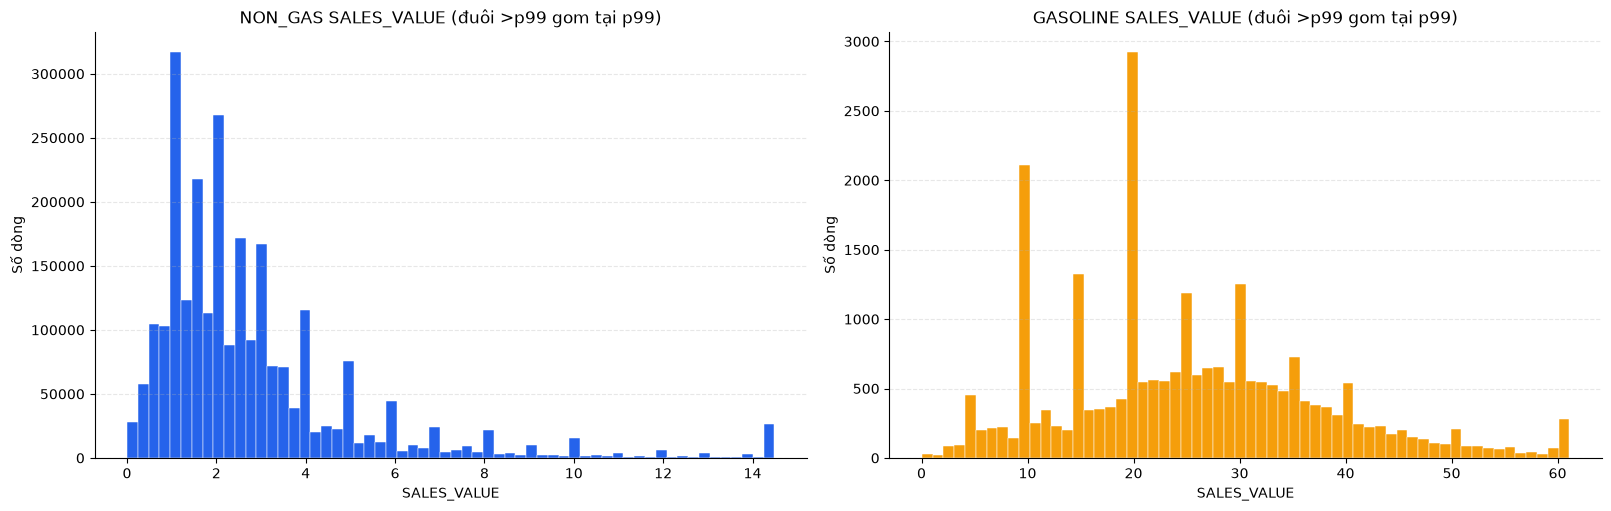

In [63]:
# SALES_VALUE — GASOLINE vs NON_GAS
sales_value_groups = {
    "NON_GAS": non_gas_lines,
    "GASOLINE": gas_lines,
}
sales_value_summary_rows = []
sales_value_extreme_products = {}

for group_name, group_lines in sales_value_groups.items():
    group_lines = group_lines.copy()
    group_lines["SALES_VALUE"] = pd.to_numeric(
        group_lines["SALES_VALUE"], errors="coerce"
    )
    sales_values = group_lines["SALES_VALUE"].dropna()
    q1 = float(sales_values.quantile(0.25))
    q3 = float(sales_values.quantile(0.75))
    iqr = q3 - q1
    p99 = float(sales_values.quantile(0.99))
    sales_value_summary_rows.append({
        "group": group_name,
        "count": int(sales_values.size),
        "min": float(sales_values.min()),
        "p1": float(sales_values.quantile(0.01)),
        "median": float(sales_values.median()),
        "p95": float(sales_values.quantile(0.95)),
        "p99": p99,
        "max": float(sales_values.max()),
        "q1": q1,
        "q3": q3,
        "IQR": iqr,
        "IQR_upper_bound": q3 + 1.5 * iqr,
    })

    extreme_lines = (
        group_lines.loc[
            group_lines["SALES_VALUE"].ge(p99),
            [
                "PRODUCT_ID", "BASKET_ID", "household_key", "QUANTITY",
                "SALES_VALUE", "STORE_ID", "DAY",
            ],
        ]
        .merge(
            product_taxonomy[[
                "PRODUCT_ID", "MANUFACTURER", "BRAND", "DEPARTMENT",
                "COMMODITY_DESC", "SUB_COMMODITY_DESC",
            ]].drop_duplicates("PRODUCT_ID"),
            on="PRODUCT_ID",
            how="left",
            validate="many_to_one",
        )
    )
    sales_value_extreme_products[group_name] = (
        extreme_lines
        .groupby(
            [
                "PRODUCT_ID", "MANUFACTURER", "BRAND", "DEPARTMENT",
                "COMMODITY_DESC", "SUB_COMMODITY_DESC",
            ],
            dropna=False,
        )
        .agg(
            n_extreme_lines=("SALES_VALUE", "size"),
            median_sales_value=("SALES_VALUE", "median"),
            max_sales_value=("SALES_VALUE", "max"),
            total_sales_value=("SALES_VALUE", "sum"),
            median_quantity=("QUANTITY", "median"),
            max_quantity=("QUANTITY", "max"),
            n_baskets=("BASKET_ID", "nunique"),
            n_households=("household_key", "nunique"),
        )
        .sort_values(
            ["max_sales_value", "n_extreme_lines", "total_sales_value"],
            ascending=[False, False, False],
        )
    )

sales_value_split_summary = (
    pd.DataFrame(sales_value_summary_rows)
    .set_index("group")
    .T
)
display(sales_value_split_summary)

for group_name, extreme_products in sales_value_extreme_products.items():
    print(f"=== TOP 30 EXTREME PRODUCTS — {group_name} (SALES_VALUE ≥ p99) ===")
    display(extreme_products.head(30))

sales_value_split_figure, sales_value_split_axes = plt.subplots(
    1, 2, figsize=(16, 5), layout="constrained"
)
for axis, (group_name, group_lines), color in zip(
    sales_value_split_axes,
    sales_value_groups.items(),
    ["#2563EB", "#F59E0B"],
    strict=True,
):
    values = pd.to_numeric(group_lines["SALES_VALUE"], errors="coerce").dropna()
    p99_limit = float(values.quantile(0.99))
    axis.hist(
        values.clip(upper=p99_limit),
        bins=60,
        color=color,
        edgecolor="white",
        linewidth=0.35,
    )
    axis.set(
        title=f"{group_name} SALES_VALUE (đuôi >p99 gom tại p99)",
        xlabel="SALES_VALUE",
        ylabel="Số dòng",
    )
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()


## 5. Top 100 dòng có QUANTITY lớn nhất và thông tin sản phẩm

Lấy 100 dòng transaction có `QUANTITY` lớn nhất, sau đó join `product.csv` theo `PRODUCT_ID` để xác định sản phẩm, brand và ba cấp taxonomy tương ứng.


In [64]:
TOP_QUANTITY_N = 100
top_quantity_transaction_columns = [
    "household_key", "BASKET_ID", "DAY", "PRODUCT_ID", "STORE_ID",
    *TRANSACTION_NUMERIC_COLUMNS,
]
top_100_quantity_lines = (
    transaction_detail[top_quantity_transaction_columns]
    .nlargest(TOP_QUANTITY_N, "QUANTITY")
    .merge(
        product_taxonomy[[
            "PRODUCT_ID", "MANUFACTURER", "BRAND", "DEPARTMENT",
            "COMMODITY_DESC", "SUB_COMMODITY_DESC", "is_fuel",
        ]].drop_duplicates("PRODUCT_ID"),
        on="PRODUCT_ID",
        how="left",
        validate="many_to_one",
    )
    .sort_values(["QUANTITY", "PRODUCT_ID"], ascending=[False, True])
    .reset_index(drop=True)
)
top_100_quantity_lines.index = top_100_quantity_lines.index + 1
top_100_quantity_lines.index.name = "rank"

top_100_quantity_product_summary = (
    top_100_quantity_lines
    .groupby(
        [
            "PRODUCT_ID", "MANUFACTURER", "BRAND", "DEPARTMENT",
            "COMMODITY_DESC", "SUB_COMMODITY_DESC", "is_fuel",
        ],
        dropna=False,
    )
    .agg(
        n_top_100_lines=("QUANTITY", "size"),
        max_quantity=("QUANTITY", "max"),
        median_quantity=("QUANTITY", "median"),
        total_quantity=("QUANTITY", "sum"),
        total_sales_value=("SALES_VALUE", "sum"),
        n_baskets=("BASKET_ID", "nunique"),
        n_households=("household_key", "nunique"),
    )
    .sort_values(
        ["max_quantity", "n_top_100_lines", "total_quantity"],
        ascending=[False, False, False],
    )
)

print(f"=== PREVIEW 20/{len(top_100_quantity_lines)} DÒNG CÓ QUANTITY LỚN NHẤT ===")
display(top_100_quantity_lines.head(20))
print("=== TỔNG HỢP SẢN PHẨM XUẤT HIỆN TRONG TOP 100 ===")
display(top_100_quantity_product_summary)


=== PREVIEW 20/100 DÒNG CÓ QUANTITY LỚN NHẤT ===


,household_key,BASKET_ID,DAY,PRODUCT_ID,STORE_ID,QUANTITY,SALES_VALUE,RETAIL_DISC,COUPON_DISC,COUPON_MATCH_DISC,MANUFACTURER,BRAND,DEPARTMENT,COMMODITY_DESC,SUB_COMMODITY_DESC,is_fuel
rank,,,,,,,,,,,,,,,,
1,630,34749153595,503,6534178,384,89638,250.00,-13.45,0.0,0.0,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True
2,2407,29392047893,181,6544236,375,85055,210.00,-8.51,0.0,0.0,69,Private,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True
3,630,29484790880,185,6534178,384,61335,150.21,-6.13,0.0,0.0,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True
4,149,28210551971,103,6534178,327,51912,110.00,-5.19,0.0,0.0,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True
5,193,32956767959,402,6534178,310,48073,121.10,-7.21,0.0,0.0,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True
6,2133,41904760458,682,6534178,433,45475,100.00,-4.55,0.0,0.0,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True
7,149,33768630428,456,6534178,327,41833,115.00,-4.18,0.0,0.0,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True
8,149,29035716247,158,6534178,327,41686,100.00,-4.17,0.0,0.0,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True
9,1406,28167562655,99,6544236,327,41485,85.00,-4.15,0.0,0.0,69,Private,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True


=== TỔNG HỢP SẢN PHẨM XUẤT HIỆN TRONG TOP 100 ===


,,,,,,,n_top_100_lines,max_quantity,median_quantity,total_quantity,total_sales_value,n_baskets,n_households
PRODUCT_ID,MANUFACTURER,BRAND,DEPARTMENT,COMMODITY_DESC,SUB_COMMODITY_DESC,is_fuel,,,,,,,
6534178,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True,71,89638,31285.0,2388029,5444.27,71,31
6544236,69,Private,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True,21,85055,32343.0,732971,1893.06,21,9
6534166,69,Private,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True,2,36140,34157.5,68315,186.94,2,2
6533889,69,Private,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True,4,32035,30322.5,122127,314.53,4,3
5716076,69,Private,KIOSK-GAS,FUEL,GASOLINE-REG UNLEADED,True,1,30080,30080.0,30080,86.01,1,1
5668996,69,Private,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,True,1,29945,29945.0,29945,61.96,1,1
